# How stock co-movement changed, 2015–2026: association rules mined year by year

**DSAI4102 Applied Data Mining · Project step 1**
Farid Abdul Rehman · Muzayyan Parkar · Mohamad Zain

**Question.** Which stocks make big moves on the same days, and how did those patterns change from one year to the next between 2015 and 2026?

**Setup in one paragraph.** Every trading day is a *basket*. The *items* in the basket are the stocks that made a major move that day, tagged with the direction (`NVDA_UP`, `IBM_DOWN`). Each calendar year is mined separately with FP-Growth, so we get one rule set per year (about 250 baskets each) and can compare the rule sets across years.

| Section | What it does | Syllabus topic |
|---|---|---|
| 1–2 | Settings, download prices | Introduction |
| 3 | Clean prices, compute returns, turn returns into items and baskets | Data preprocessing |
| 4 | Mine frequent itemsets and rules per year (FP-Growth, checked against Apriori) | Frequent itemsets and association rules |
| 5 | Visuals for every year: price paths, co-movement heatmap, rule network | Association rules |
| 6 | Compare the years: rule counts, overlap, rules that are stable, emerged or disappeared | Association rules |
| 7 | Are the rules real? Support sweep and a shuffled-data test | Association rules |
| 8 | Cross-check: do stocks cluster by sector, and does that change? | Clustering |

## 1. Settings

Everything that can change a result lives in this one cell. Re-run the notebook from the top after changing anything here.

In [1]:
from pathlib import Path
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D

from mlxtend.frequent_patterns import fpgrowth, apriori, association_rules
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.spatial.distance import pdist
from sklearn.metrics import adjusted_rand_score

# ---- study window ---------------------------------------------------------
START_YEAR, END_YEAR = 2015, 2026
DOWNLOAD_START = "2014-06-01"   # extra months so the rolling volatility is ready by January 2015
DOWNLOAD_END = "2026-11-14"     # fixed end date (exclusive) so every run uses the same data

# ---- the 40 stocks, in four groups (from the proposal) --------------------
GROUPS = {
    "AI enablers": ["NVDA", "AMD", "AVGO", "TSM", "MU", "QCOM", "INTC", "AMAT", "LRCX", "ASML"],
    "Big Tech": ["AAPL", "MSFT", "GOOGL", "AMZN", "META", "ORCL", "NFLX", "TSLA"],
    "Traditional software": ["ADBE", "CRM", "IBM", "CSCO", "CHGG", "INTU", "SAP", "ACN", "NOW", "WDAY", "ADSK", "CTSH"],
    "Non-tech baseline": ["JPM", "XOM", "JNJ", "PG", "KO", "WMT", "UNH", "CAT", "HD", "PFE"],
}
MARKET = "SPY"                  # S&P 500 ETF, used only when RETURN_MODE = "excess"

# ---- what counts as a "major move" ----------------------------------------
RETURN_MODE = "raw"             # "raw" = the stock's own daily return; "excess" = return minus the market's
MOVE_METHOD = "zscore"          # "zscore" = big relative to the stock's own recent volatility; "fixed" = fixed %
Z_K = 1.0                       # zscore: |return| must be at least Z_K times the recent standard deviation
VOL_WINDOW = 60                 # zscore: trading days used to measure recent volatility
FIXED_PCT = 0.02                # fixed: |return| must be at least 2%

# ---- mining thresholds ----------------------------------------------------
MIN_SUPPORT = 0.05              # itemset must appear on at least 5% of the year's trading days (about 13 days)
MIN_CONFIDENCE = 0.50
MIN_LIFT = 1.5
MAX_LEN = 3                     # largest itemset size

# ---- comparison and robustness settings -----------------------------------
SPLIT_YEAR = 2023               # first full calendar year after ChatGPT's release (30 Nov 2022)
SUPPORT_GRID = [0.03, 0.04, 0.05, 0.06, 0.08, 0.10]
N_SHUFFLES = 5
SEED = 42

DATA_DIR, OUT_DIR = Path("data"), Path("outputs/step1")   # step 1 outputs kept apart from outputs/final and outputs/events
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
# Plot style: one colour per stock group, used the same way in every figure.
INK, INK_SOFT, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
GROUP_COLORS = dict(zip(GROUPS, ["#2a78d6", "#eb6834", "#1baf7a", "#898781"]))   # baseline group is grey

# Lift colour scale: blue = together less often than chance, grey = chance, red = more often than chance.
LIFT_CMAP = LinearSegmentedColormap.from_list("lift", ["#184f95", "#6da7ec", "#f0efec", "#ec8a7c", "#b3261e"])
LIFT_CMAP.set_bad(SURFACE)
# One-hue scale for "how much".
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#6da7ec", "#256abf", "#0d366b"])
BLUES.set_bad(SURFACE)

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 9, "text.color": INK,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_SOFT, "axes.titlecolor": INK,
    "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_SOFT, "ytick.labelcolor": INK_SOFT,
    "grid.color": GRID, "grid.linewidth": 0.6, "lines.linewidth": 2,
    "figure.dpi": 110, "savefig.dpi": 170, "savefig.bbox": "tight",
})


def save(fig, name):
    # Save a figure into outputs/step1/ so it can go straight into the slides or the report.
    fig.savefig(OUT_DIR / f"{name}.png")


def group_legend(fig, extra=(), where="upper"):
    # One shared legend above (or below) the charts naming the four stock groups, plus any extra entries.
    handles = [Line2D([], [], marker="o", ls="", color=c, markersize=7, label=g) for g, c in GROUP_COLORS.items()]
    handles += list(extra)
    fig.legend(handles=handles, loc=f"outside {where} center", ncol=len(handles), frameon=False)

## 2. Data collection

Daily prices come from Yahoo Finance through the `yfinance` library. We use the **adjusted close** (`auto_adjust=True`), which corrects for stock splits and dividends. Without that, NVDA's 10-for-1 split in 2024 would look like a 90% crash.

The first run downloads the data and saves it to `data/prices.csv`. Later runs read that file, so the whole group works from exactly the same dataset, and the file can be submitted with the report. Delete the file to force a fresh download.

In [3]:
def load_prices(tickers, start, end, cache_path):
    # Return a table of adjusted closing prices: one row per trading day, one column per ticker.
    if cache_path.exists():
        prices = pd.read_csv(cache_path, index_col=0, parse_dates=True)
        if set(tickers) <= set(prices.columns):
            print(f"Loaded {cache_path} ({prices.shape[0]} days x {prices.shape[1]} tickers)")
            return prices[tickers].sort_index()
        print("Saved file is missing some tickers, downloading again.")

    import yfinance as yf
    raw = yf.download(tickers, start=start, end=end, auto_adjust=True, progress=False)
    prices = raw["Close"]
    prices.index = pd.to_datetime(prices.index).tz_localize(None)
    prices = prices.reindex(columns=tickers)           # a ticker that failed to download becomes an empty column
    prices.to_csv(cache_path)
    print(f"Downloaded and saved {cache_path} ({prices.shape[0]} days x {prices.shape[1]} tickers)")
    return prices.sort_index()


ALL_TICKERS = [t for members in GROUPS.values() for t in members]
prices_raw = load_prices(ALL_TICKERS + [MARKET], DOWNLOAD_START, DOWNLOAD_END, DATA_DIR / "prices.csv")
prices_raw.tail(3)

Loaded data/prices.csv (3134 days x 41 tickers)


,NVDA,AMD,AVGO,TSM,MU,QCOM,INTC,AMAT,LRCX,ASML,...,XOM,JNJ,PG,KO,WMT,UNH,CAT,HD,PFE,SPY
Date,,,,,,,,,,,,,,,,,,,,,
2026-11-11,173.729996,552.900024,345.220001,413.350006,811.299988,176.570007,62.500000,395.079987,235.880005,1534.420044,...,166.710007,280.410004,167.669998,97.570000,125.669998,402.940002,601.609985,351.309998,29.450001,759.809998
2026-11-12,166.190002,585.299988,364.359985,405.489990,798.440002,177.139999,61.200001,380.950012,233.779999,1497.119995,...,169.779999,283.519989,168.029999,97.440002,126.190002,405.130005,605.280029,348.260010,28.830000,757.119995
2026-11-13,162.850006,534.059998,347.010010,398.730011,778.309998,172.470001,59.660000,370.500000,225.919998,1495.160034,...,170.589996,285.750000,169.800003,99.250000,128.089996,407.459991,600.200012,348.690002,28.889999,754.369995


## 3. Preprocessing

Three steps turn prices into baskets:

1. **Clean.** Drop any ticker that is missing more than 2% of days (for example a stock that listed after 2014). Fill short gaps of up to 3 days with the last known price.
2. **Returns.** Daily return = today's price / yesterday's price − 1.
3. **Discretise.** A return becomes an item only if it is a *major move*. This answers the professor's question about what "major" means.

**Why the default is a z-score and not a fixed percentage.** A fixed ±2% rule treats NVDA and Coca-Cola the same, but NVDA moves 2% on an ordinary day and Coca-Cola almost never does. The baskets would then be full of volatile stocks and the rules would mostly describe volatility. With the z-score rule, a move counts when it is at least `Z_K` times the stock's own standard deviation over the previous `VOL_WINDOW` days. The window is shifted by one day, so today's threshold only uses information from before today. `MOVE_METHOD = "fixed"` switches to the fixed rule for comparison.

In [4]:
def clean_prices(prices, max_missing=0.02, max_gap=3):
    # Drop tickers with too many missing days, then fill short gaps with the last known price.
    missing_share = prices.isna().mean()
    dropped = missing_share[missing_share > max_missing].index.tolist()
    cleaned = prices.drop(columns=dropped).ffill(limit=max_gap)
    return cleaned, dropped


prices, dropped = clean_prices(prices_raw)
print("Dropped tickers:", dropped if dropped else "none")
if MARKET in dropped and RETURN_MODE == "excess":
    raise ValueError(f"{MARKET} is needed for RETURN_MODE='excess' but has too much missing data.")

# Keep only the stocks that survived cleaning, group by group.
GROUPS_CLEAN = {g: [t for t in members if t in prices.columns] for g, members in GROUPS.items()}
TICKERS = [t for members in GROUPS_CLEAN.values() for t in members]
GROUP_OF = {t: g for g, members in GROUPS_CLEAN.items() for t in members}
print({g: len(m) for g, m in GROUPS_CLEAN.items()}, "->", len(TICKERS), "stocks")

Dropped tickers: none
{'AI enablers': 10, 'Big Tech': 8, 'Traditional software': 12, 'Non-tech baseline': 10} -> 40 stocks


In [5]:
# Daily returns. raw_returns is always the stock's own return (used for the price charts).
all_returns = prices / prices.shift(1) - 1
raw_returns = all_returns[TICKERS]

if RETURN_MODE == "excess":
    # Subtract the market's return, so a day when everything falls together no longer counts as co-movement.
    returns = raw_returns.sub(all_returns[MARKET], axis=0)
else:
    returns = raw_returns

returns.loc[str(START_YEAR):].describe().T[["mean", "std", "min", "max"]].head()

,mean,std,min,max
NVDA,0.002409,0.030292,-0.187558,0.298068
AMD,0.002482,0.037972,-0.242291,0.522901
AVGO,0.001595,0.025033,-0.199129,0.244326
TSM,0.001292,0.021272,-0.140341,0.126522
MU,0.001587,0.032841,-0.198186,0.192916


In [6]:
def find_major_moves(returns, method, z_k, vol_window, fixed_pct):
    # Turn returns into True/False items. Columns: one <TICKER>_UP and one <TICKER>_DOWN per stock.
    if method == "zscore":
        typical_move = returns.rolling(vol_window).std().shift(1)   # volatility known before today
        score = returns / typical_move
        up, down = score >= z_k, score <= -z_k
    elif method == "fixed":
        up, down = returns >= fixed_pct, returns <= -fixed_pct
    else:
        raise ValueError("MOVE_METHOD must be 'zscore' or 'fixed'")
    up.columns = [f"{t}_UP" for t in returns.columns]
    down.columns = [f"{t}_DOWN" for t in returns.columns]
    return pd.concat([up, down], axis=1)


items = find_major_moves(returns, MOVE_METHOD, Z_K, VOL_WINDOW, FIXED_PCT)
items = items.loc[str(START_YEAR):str(END_YEAR)]                    # keep only the study window

# One basket table per year: rows = trading days, columns = items, True = the item is in that day's basket.
YEARS = [y for y in range(START_YEAR, END_YEAR + 1) if (items.index.year == y).any()]
baskets_by_year = {y: items[items.index.year == y] for y in YEARS}

print(f"{len(items)} baskets (trading days), {items.shape[1]} possible items")

2985 baskets (trading days), 80 possible items


In [7]:
# What a few baskets look like when written out as transactions.
example = items.tail(5)
for day, row in example.iterrows():
    print(day.date(), "->", list(row.index[row.to_numpy()]))

2026-11-09 -> ['AMD_UP', 'AVGO_UP', 'TSM_UP', 'MU_UP', 'QCOM_UP', 'AMAT_UP', 'LRCX_UP', 'ASML_UP', 'AAPL_UP', 'MSFT_UP', 'AMZN_UP', 'META_UP', 'TSLA_UP', 'CSCO_UP', 'JPM_UP', 'JNJ_UP', 'PG_UP', 'CAT_UP', 'HD_UP', 'NVDA_DOWN']
2026-11-10 -> ['AVGO_UP', 'UNH_UP', 'NVDA_DOWN', 'MSFT_DOWN']
2026-11-11 -> ['NVDA_UP', 'AMD_UP', 'AVGO_UP', 'TSM_UP', 'MU_UP', 'INTC_UP', 'AMAT_UP', 'LRCX_UP', 'AAPL_UP', 'ORCL_UP', 'CSCO_UP', 'CAT_UP', 'MSFT_DOWN']
2026-11-12 -> ['AMD_UP', 'AVGO_UP', 'XOM_UP', 'NVDA_DOWN', 'NFLX_DOWN', 'PFE_DOWN']
2026-11-13 -> ['META_UP', 'WDAY_UP', 'KO_UP', 'AMD_DOWN', 'AVGO_DOWN', 'CSCO_DOWN']


In [8]:
# Basket statistics per year. A year with big average baskets is a year when many stocks moved on the same days.
def ticker_of(item):
    return item.rsplit("_", 1)[0]

basket_stats = pd.DataFrame({
    "trading_days": {y: len(b) for y, b in baskets_by_year.items()},
    "avg_items_per_day": {y: b.sum(axis=1).mean() for y, b in baskets_by_year.items()},
    "empty_days": {y: int((b.sum(axis=1) == 0).sum()) for y, b in baskets_by_year.items()},
    "avg_item_support": {y: b.mean().mean() for y, b in baskets_by_year.items()},
})
basket_stats.round(3)

,trading_days,avg_items_per_day,empty_days,avg_item_support
2015,252,10.365,3,0.130
2016,252,9.540,5,0.119
2017,251,9.347,1,0.117
2018,251,11.936,1,0.149
2019,252,8.698,9,0.109
2020,253,10.925,13,0.137
2021,252,11.175,4,0.140
2022,251,11.625,7,0.145
2023,250,9.580,1,0.120
2024,252,10.222,2,0.128


**Note on basket counts.** Each year has about 250 baskets and up to 80 possible items. That is small for association rule mining, so a pattern can clear the thresholds by luck. Section 7 tests for exactly that. The last year is a partial year, so its counts rest on fewer days.

## 4. Mining association rules, one year at a time

For each year we run **FP-Growth** to get the frequent itemsets, then build rules from them.

- **Support** of an itemset = share of that year's trading days on which all its items appeared.
- **Confidence** of A → B = of the days A happened, the share on which B also happened.
- **Lift** of A → B = confidence divided by B's own support. Lift 1 means A tells us nothing about B. Lift 3 means B is three times as likely as usual on days when A happens.

Lift matters here because of how the items are built: with `Z_K = 1`, each item appears on roughly 10–15% of days, so high confidence alone is rare, and lift is what tells us a pair moves together more than chance.

In [9]:
def mine_rules(basket, min_support, min_confidence, min_lift, max_len, algorithm="fpgrowth"):
    # Mine one basket table. Returns (frequent itemsets, rules) as two DataFrames.
    miner = fpgrowth if algorithm == "fpgrowth" else apriori
    itemsets = miner(basket, min_support=min_support, use_colnames=True, max_len=max_len)
    if itemsets.empty:
        return itemsets, pd.DataFrame()

    rules = association_rules(itemsets, num_itemsets=len(basket), metric="confidence", min_threshold=min_confidence)
    rules = rules[rules["lift"] >= min_lift].copy()
    if rules.empty:
        return itemsets, pd.DataFrame()

    # Readable text versions of the two sides, plus a single name used to track a rule across years.
    rules["antecedent"] = rules["antecedents"].apply(lambda s: ", ".join(sorted(s)))
    rules["consequent"] = rules["consequents"].apply(lambda s: ", ".join(sorted(s)))
    rules["rule"] = rules["antecedent"] + " -> " + rules["consequent"]

    # Describe each rule: how many items, does it link different stock groups, are the moves all one direction.
    all_items = [set(a) | set(c) for a, c in zip(rules["antecedents"], rules["consequents"])]
    rules["n_items"] = [len(s) for s in all_items]
    rules["cross_group"] = [len({GROUP_OF[ticker_of(i)] for i in s}) > 1 for s in all_items]
    directions = [{i.rsplit("_", 1)[1] for i in s} for s in all_items]
    rules["direction"] = [d.pop() if len(d) == 1 else "MIXED" for d in directions]

    keep = ["rule", "antecedent", "consequent", "support", "confidence", "lift",
            "antecedent support", "consequent support", "n_items", "cross_group", "direction"]
    return itemsets, rules[keep].sort_values("lift", ascending=False).reset_index(drop=True)

In [10]:
itemsets_by_year, rules_by_year = {}, {}
for year in YEARS:
    itemsets_by_year[year], rules_by_year[year] = mine_rules(
        baskets_by_year[year], MIN_SUPPORT, MIN_CONFIDENCE, MIN_LIFT, MAX_LEN)
    print(f"{year}: {len(itemsets_by_year[year]):>6} frequent itemsets, {len(rules_by_year[year]):>6} rules")

if all(r.empty for r in rules_by_year.values()):
    raise ValueError("No rule passed the thresholds in any year. Lower MIN_SUPPORT, MIN_CONFIDENCE or MIN_LIFT.")

# All years stacked into one table, with a year column. This is the main output of the notebook.
rules_all = pd.concat(
    [r.assign(year=y) for y, r in rules_by_year.items() if not r.empty], ignore_index=True)
rules_all.to_csv(OUT_DIR / "rules_by_year.csv", index=False)
print(f"\n{len(rules_all)} rules in total, saved to {OUT_DIR / 'rules_by_year.csv'}")

2015:    857 frequent itemsets,    852 rules
2016:    688 frequent itemsets,    969 rules


2017:    259 frequent itemsets,    131 rules


2018:   4214 frequent itemsets,  10338 rules


2019:    284 frequent itemsets,    256 rules


2020:   6397 frequent itemsets,  19941 rules
2021:   1422 frequent itemsets,   3030 rules


2022:   5793 frequent itemsets,  16402 rules
2023:    368 frequent itemsets,    331 rules
2024:    433 frequent itemsets,    525 rules
2025:    374 frequent itemsets,    496 rules
2026:    833 frequent itemsets,   1450 rules



54721 rules in total, saved to outputs/step1/rules_by_year.csv


### FP-Growth against Apriori

Both algorithms must return exactly the same frequent itemsets, because they answer the same question in different ways. Apriori generates candidate itemsets level by level and counts each against the data. FP-Growth compresses the baskets into a tree once and reads the itemsets from the tree without generating candidates. This cell checks that the outputs match on the busiest year and compares the running time.

In [11]:
busiest_year = max(YEARS, key=lambda y: len(itemsets_by_year[y]))
basket = baskets_by_year[busiest_year]

timings, found = {}, {}
for algorithm in ["fpgrowth", "apriori"]:
    start = time.perf_counter()
    itemsets, _ = mine_rules(basket, MIN_SUPPORT, MIN_CONFIDENCE, MIN_LIFT, MAX_LEN, algorithm)
    timings[algorithm] = time.perf_counter() - start
    found[algorithm] = set(itemsets["itemsets"]) if not itemsets.empty else set()

print(f"Year {busiest_year}: FP-Growth {timings['fpgrowth']:.2f}s, Apriori {timings['apriori']:.2f}s")
print("Same frequent itemsets from both algorithms:", found["fpgrowth"] == found["apriori"],
      f"({len(found['fpgrowth'])} itemsets)")

Year 2020: FP-Growth 0.34s, Apriori 0.21s
Same frequent itemsets from both algorithms: True (6397 itemsets)


## 5. A picture of every year

Three views, each drawn once per year so the years can be compared at a glance:

- **5.1 Price paths.** Average cumulative return of each group during the year. This is the plain "what happened" view.
- **5.2 Co-movement heatmap.** For every pair of stocks, how much more often they made a major move in the same direction on the same day than chance would predict (the pair's lift).
- **5.3 Rule network.** A line joins two stocks when the year's rule set contains a rule linking them.

`show_year(2023)` in 5.4 draws a large, labelled version for any single year together with its strongest rules.

In [12]:
def year_grid(n_cols=4, panel=(3.2, 2.7), **kwargs):
    # A grid of small charts, one per year. Returns the figure and a {year: axis} dictionary.
    n_rows = int(np.ceil(len(YEARS) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(panel[0] * n_cols, panel[1] * n_rows),
                             layout="constrained", **kwargs)
    axes = np.atleast_1d(axes).ravel()
    for ax in axes[len(YEARS):]:
        ax.set_visible(False)
    return fig, dict(zip(YEARS, axes))

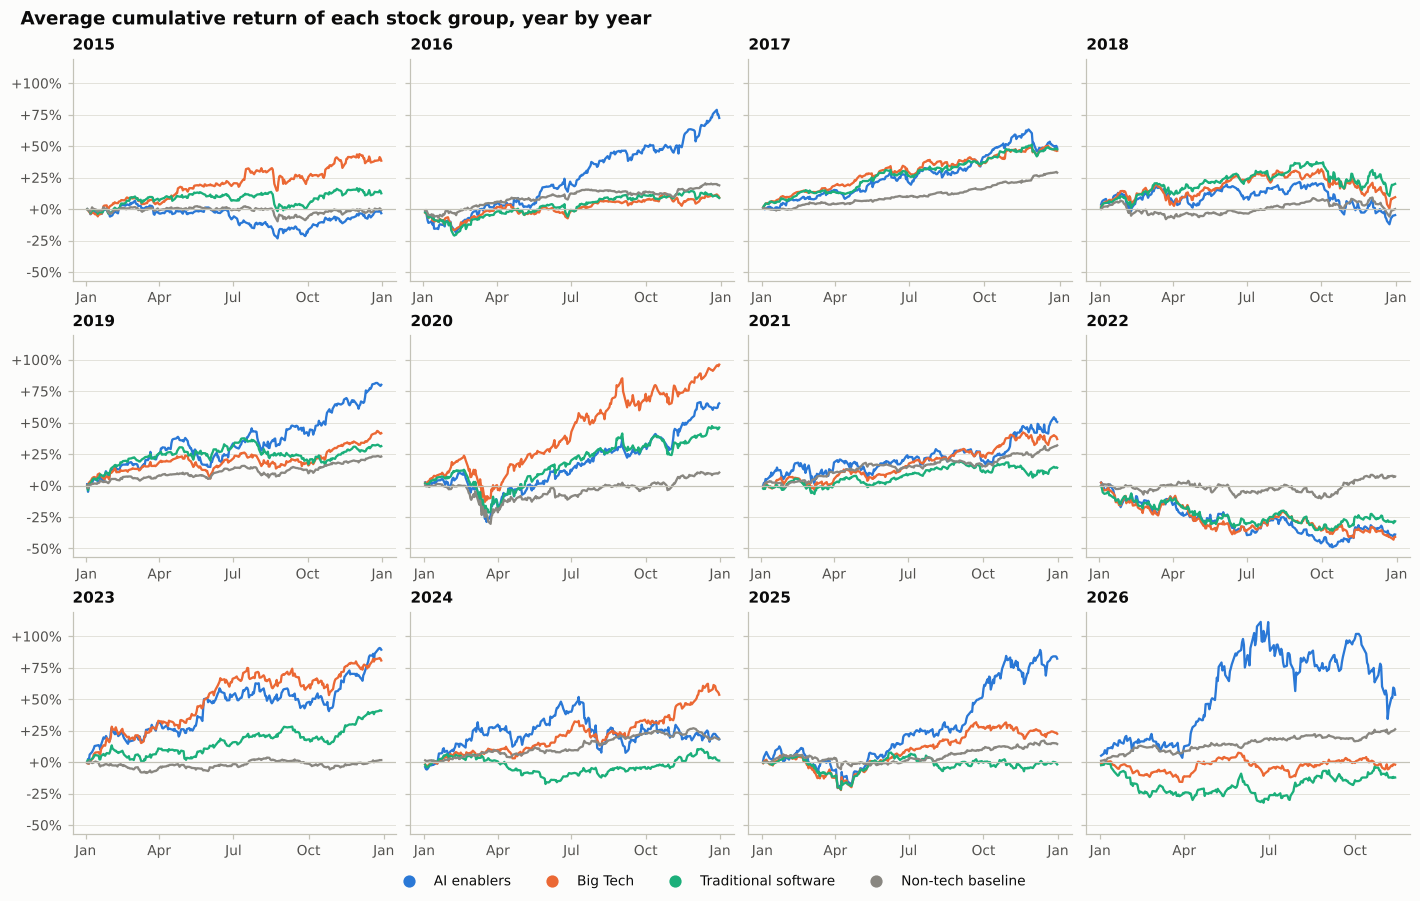

In [13]:
# 5.1 Price paths: average cumulative return of each group, restarted at 0% every January.
fig, axes = year_grid(sharey=True)
for year, ax in axes.items():
    year_returns = raw_returns[raw_returns.index.year == year]
    for group, members in GROUPS_CLEAN.items():
        path = (1 + year_returns[members].mean(axis=1)).cumprod() - 1
        ax.plot(path.index, path * 100, color=GROUP_COLORS[group], lw=1.5)
    ax.axhline(0, color=AXIS, lw=0.8)
    ax.set_title(str(year))
    ax.grid(axis="y")
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:+.0f}%")
group_legend(fig, where="lower")
fig.suptitle("Average cumulative return of each stock group, year by year", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
save(fig, "5_1_price_paths_by_year")
plt.show()

In [14]:
def pair_lift_matrix(basket, tickers):
    # For every pair of stocks: lift of "both made a major move in the same direction on the same day".
    up = basket[[f"{t}_UP" for t in tickers]].to_numpy(dtype=float)
    down = basket[[f"{t}_DOWN" for t in tickers]].to_numpy(dtype=float)
    n_days = len(basket)
    together = (up.T @ up + down.T @ down) / n_days                 # share of days both moved the same way
    by_chance = np.outer(up.mean(0), up.mean(0)) + np.outer(down.mean(0), down.mean(0))
    lift = np.divide(together, by_chance, out=np.full_like(together, np.nan), where=by_chance > 0)
    np.fill_diagonal(lift, np.nan)                                  # a stock with itself is not interesting
    return pd.DataFrame(lift, index=tickers, columns=tickers)


lift_by_year = {y: pair_lift_matrix(baskets_by_year[y], TICKERS) for y in YEARS}

# Where each group starts and ends along the heatmap axes.
group_sizes = [len(m) for m in GROUPS_CLEAN.values()]
group_edges = np.cumsum(group_sizes)[:-1] - 0.5
group_mids = np.cumsum(group_sizes) - np.array(group_sizes) / 2 - 0.5
LIFT_TICKS = {-2: "0.25x or less", -1: "0.5x", 0: "1x (chance)", 1: "2x", 2: "4x or more"}


def draw_lift_heatmap(ax, lift, show_tickers=False):
    # Draw one pairwise-lift heatmap. Colour is log2(lift), so 2x and 0.5x sit the same distance from chance.
    logged = np.log2(lift.clip(lower=0.25, upper=4).to_numpy())
    image = ax.imshow(logged, cmap=LIFT_CMAP, vmin=-2, vmax=2)
    for edge in group_edges:                                        # gaps between the stock groups
        ax.axhline(edge, color=SURFACE, lw=2)
        ax.axvline(edge, color=SURFACE, lw=2)
    ax.spines[:].set_visible(False)
    ax.tick_params(length=0)
    if show_tickers:
        ax.set_xticks(range(len(lift)), lift.columns, rotation=90, fontsize=6.5)
        ax.set_yticks(range(len(lift)), lift.index, fontsize=6.5)
    else:
        ax.set_xticks([])
        ax.set_yticks([])
    return image

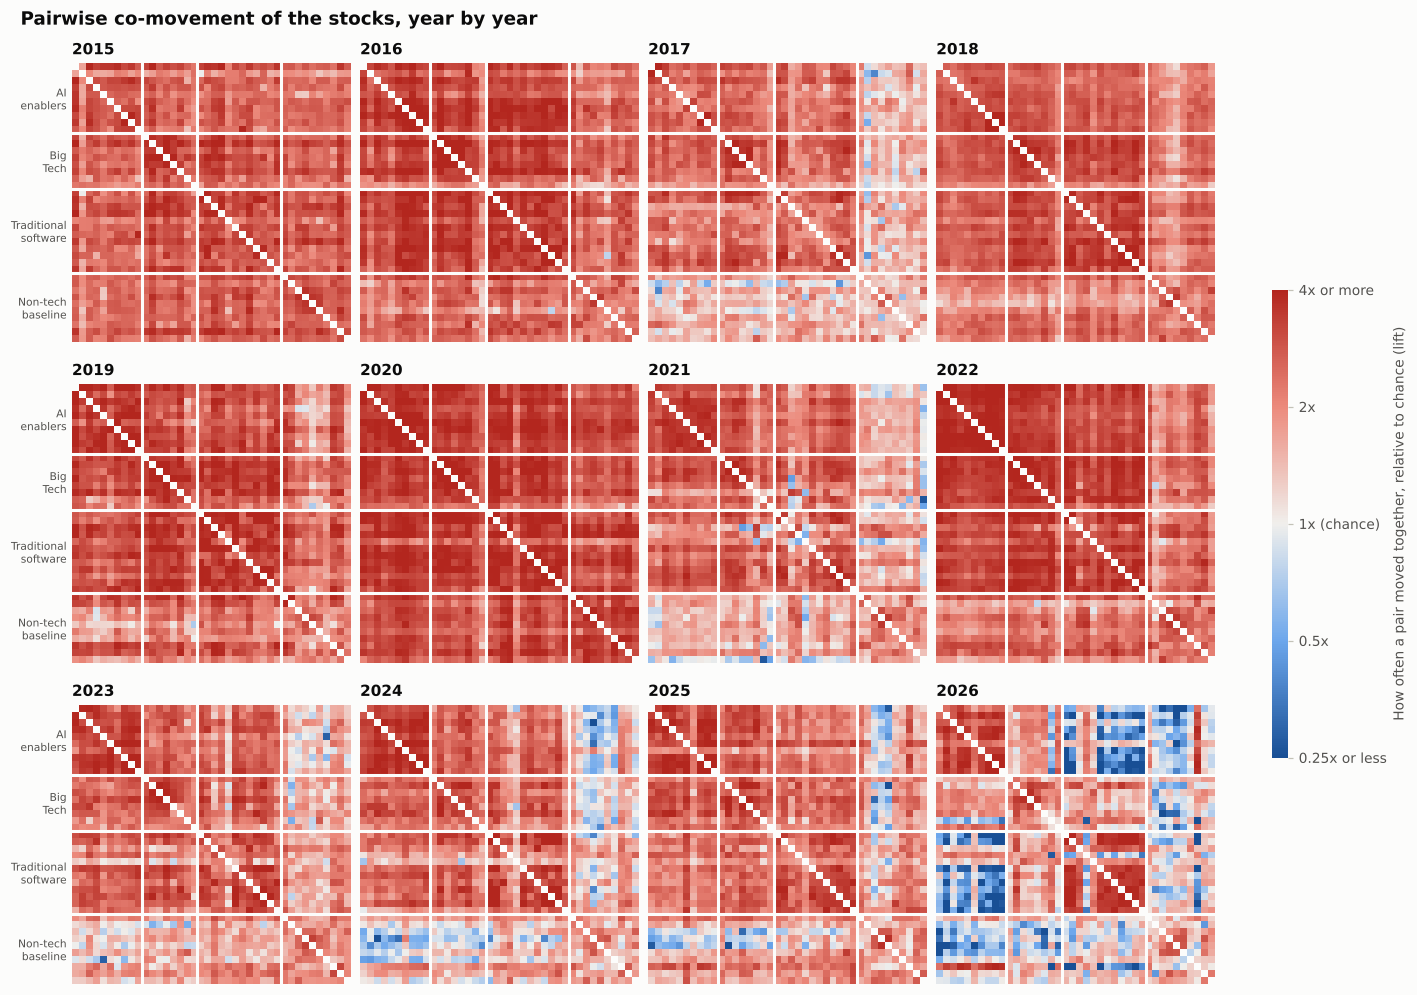

In [15]:
# 5.2 Co-movement heatmap for every year. Stocks are in the same order in every panel, grouped by sector.
fig, axes = year_grid(panel=(3.2, 3.0))
for i, (year, ax) in enumerate(axes.items()):
    image = draw_lift_heatmap(ax, lift_by_year[year])
    ax.set_title(str(year))
    if i % 4 == 0:                                                  # name the groups on the left-hand panels
        ax.set_yticks(group_mids, [g.replace(" ", "\n") for g in GROUPS_CLEAN], fontsize=7)
bar = fig.colorbar(image, ax=list(axes.values()), shrink=0.5, aspect=30, ticks=list(LIFT_TICKS))
bar.ax.set_yticklabels(list(LIFT_TICKS.values()))
bar.outline.set_visible(False)
bar.set_label("How often a pair moved together, relative to chance (lift)")
fig.suptitle("Pairwise co-movement of the stocks, year by year", x=0.01, ha="left", fontsize=12, fontweight="bold")
save(fig, "5_2_comovement_heatmaps_by_year")
plt.show()

In [16]:
def circle_positions(tickers):
    # Place the stocks evenly around a circle, in group order. The layout is the same for every year.
    angles = np.pi / 2 - np.linspace(0, 2 * np.pi, len(tickers), endpoint=False)
    return {t: (np.cos(a), np.sin(a)) for t, a in zip(tickers, angles)}


def linked_pairs(rules):
    # Pairs of stocks joined by a two-item rule this year: {(ticker, ticker): strongest lift for the pair}.
    strongest = {}
    if rules.empty:
        return strongest
    pairs = rules[rules["n_items"] == 2]
    for a, c, lift in zip(pairs["antecedent"], pairs["consequent"], pairs["lift"]):
        pair = tuple(sorted([ticker_of(a), ticker_of(c)]))
        strongest[pair] = max(lift, strongest.get(pair, 0))
    return strongest


POSITIONS = circle_positions(TICKERS)
CROSS_GROUP_LINK = Line2D([], [], color=INK_SOFT, lw=1.2, label="Link between two groups")   # legend entry


def draw_rule_network(ax, rules, show_tickers=False):
    # Draw the rule network for one year. Returns the number of linked pairs.
    pairs = linked_pairs(rules)
    segments, colors = [], []
    for a, b in pairs:
        segments.append([POSITIONS[a], POSITIONS[b]])
        same_group = GROUP_OF[a] == GROUP_OF[b]
        colors.append(GROUP_COLORS[GROUP_OF[a]] if same_group else INK_SOFT)   # dark line = link across groups
    ax.add_collection(LineCollection(segments, colors=colors, linewidths=0.7, alpha=0.45))
    xy = np.array([POSITIONS[t] for t in TICKERS])
    ax.scatter(xy[:, 0], xy[:, 1], s=60 if show_tickers else 22, zorder=3,
               c=[GROUP_COLORS[GROUP_OF[t]] for t in TICKERS], edgecolors=SURFACE, linewidths=1)
    if show_tickers:
        for t, (x, y) in POSITIONS.items():
            ax.text(1.15 * x, 1.15 * y, t, ha="center", va="center", fontsize=7, color=INK_SOFT)
    limit = 1.3 if show_tickers else 1.1
    ax.set(xlim=(-limit, limit), ylim=(-limit, limit), aspect="equal")
    ax.axis("off")
    return len(pairs)

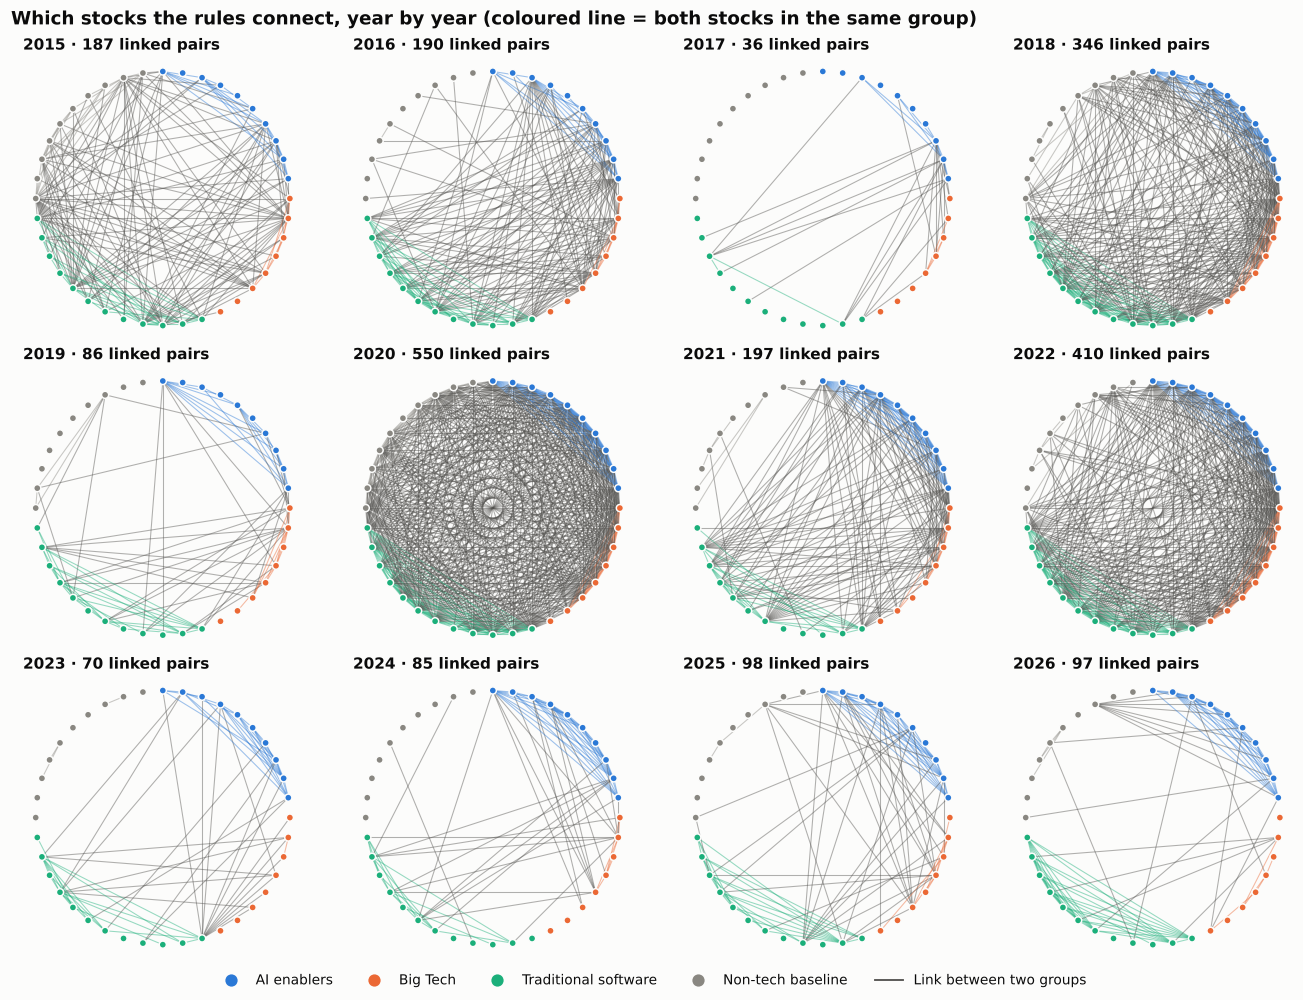

In [17]:
# 5.3 Rule network for every year. A line joins two stocks if a two-item rule links them that year.
fig, axes = year_grid(panel=(3.0, 3.0))
for year, ax in axes.items():
    n_pairs = draw_rule_network(ax, rules_by_year[year])
    ax.set_title(f"{year} · {n_pairs} linked pairs")
group_legend(fig, extra=[CROSS_GROUP_LINK], where="lower")
fig.suptitle("Which stocks the rules connect, year by year (coloured line = both stocks in the same group)",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
save(fig, "5_3_rule_networks_by_year")
plt.show()

### 5.4 Close-up of a single year

Call `show_year(year)` for any year. It draws the labelled heatmap and network and lists the year's strongest rules.

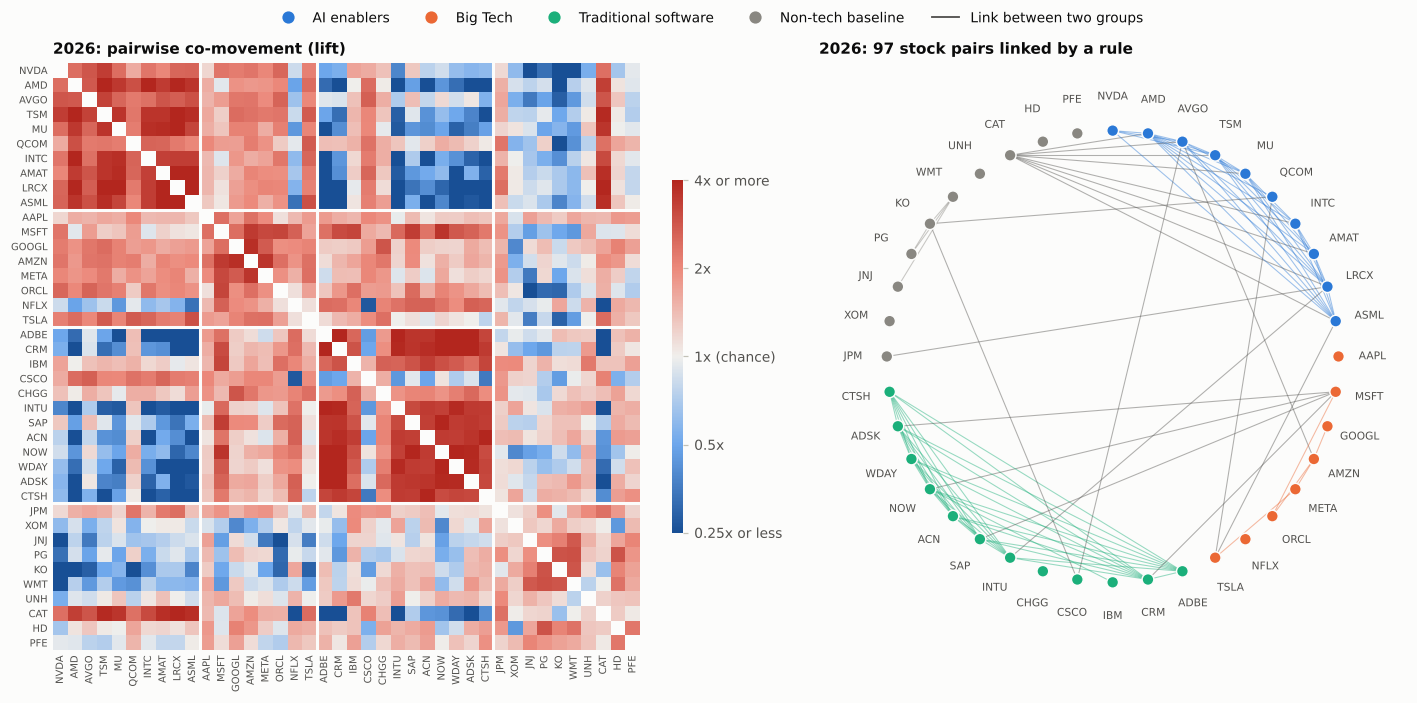

Strongest rules in 2026 (by lift), out of 1450:


,rule,support,confidence,lift,cross_group,direction
0,"INTC_DOWN, LRCX_DOWN -> AMD_DOWN",0.068,0.833,7.935,False,DOWN
1,"AMD_DOWN -> INTC_DOWN, LRCX_DOWN",0.068,0.652,7.935,False,DOWN
2,"AMD_DOWN -> AMAT_DOWN, INTC_DOWN",0.055,0.522,7.617,False,DOWN
3,"LRCX_DOWN, MU_DOWN -> AMD_DOWN",0.073,0.800,7.617,False,DOWN
4,"AMD_DOWN -> LRCX_DOWN, MU_DOWN",0.073,0.696,7.617,False,DOWN
5,"AMAT_DOWN, INTC_DOWN -> AMD_DOWN",0.055,0.800,7.617,False,DOWN
6,"CAT_DOWN, INTC_DOWN -> AMD_DOWN",0.050,0.786,7.481,True,DOWN
7,"AMD_DOWN -> ASML_DOWN, INTC_DOWN",0.064,0.609,7.406,False,DOWN
8,"AMAT_DOWN, MU_DOWN -> AMD_DOWN",0.064,0.778,7.406,False,DOWN
9,"ASML_DOWN, INTC_DOWN -> AMD_DOWN",0.064,0.778,7.406,False,DOWN


In [18]:
def show_year(year, top=10):
    # Large labelled heatmap and network for one year, plus its strongest rules.
    fig, (left, right) = plt.subplots(1, 2, figsize=(13, 6.3), layout="constrained")
    image = draw_lift_heatmap(left, lift_by_year[year], show_tickers=True)
    left.set_title(f"{year}: pairwise co-movement (lift)")
    bar = fig.colorbar(image, ax=left, shrink=0.6, aspect=30, ticks=list(LIFT_TICKS))
    bar.ax.set_yticklabels(list(LIFT_TICKS.values()))
    bar.outline.set_visible(False)
    n_pairs = draw_rule_network(right, rules_by_year[year], show_tickers=True)
    right.set_title(f"{year}: {n_pairs} stock pairs linked by a rule")
    group_legend(fig, extra=[CROSS_GROUP_LINK])
    save(fig, f"5_4_close_up_{year}")
    plt.show()

    rules = rules_by_year[year]
    if rules.empty:
        print(f"No rules passed the thresholds in {year}.")
    else:
        print(f"Strongest rules in {year} (by lift), out of {len(rules)}:")
        display(rules.head(top)[["rule", "support", "confidence", "lift", "cross_group", "direction"]].round(3))


show_year(YEARS[-1])

## 6. How the rule sets changed across the years

### 6.1 Summary of each year

In [19]:
summary = basket_stats[["trading_days", "avg_items_per_day"]].copy()
summary["frequent_itemsets"] = {y: len(s) for y, s in itemsets_by_year.items()}
summary["rules"] = {y: len(r) for y, r in rules_by_year.items()}
summary["median_lift"] = {y: r["lift"].median() if not r.empty else np.nan for y, r in rules_by_year.items()}
summary["cross_group_share"] = {y: r["cross_group"].mean() if not r.empty else np.nan for y, r in rules_by_year.items()}
summary["linked_pairs"] = {y: len(linked_pairs(r)) for y, r in rules_by_year.items()}
summary.to_csv(OUT_DIR / "yearly_summary.csv")
summary.round(3)

,trading_days,avg_items_per_day,frequent_itemsets,rules,median_lift,cross_group_share,linked_pairs
2015,252,10.365,857,852,4.789,0.754,187
2016,252,9.540,688,969,5.327,0.773,190
2017,251,9.347,259,131,4.459,0.649,36
2018,251,11.936,4214,10338,4.834,0.868,346
2019,252,8.698,284,256,5.444,0.285,86
2020,253,10.925,6397,19941,6.024,0.903,550
2021,252,11.175,1422,3030,4.964,0.749,197
2022,251,11.625,5793,16402,4.781,0.864,410
2023,250,9.580,368,331,4.926,0.384,70
2024,252,10.222,433,525,5.032,0.290,85


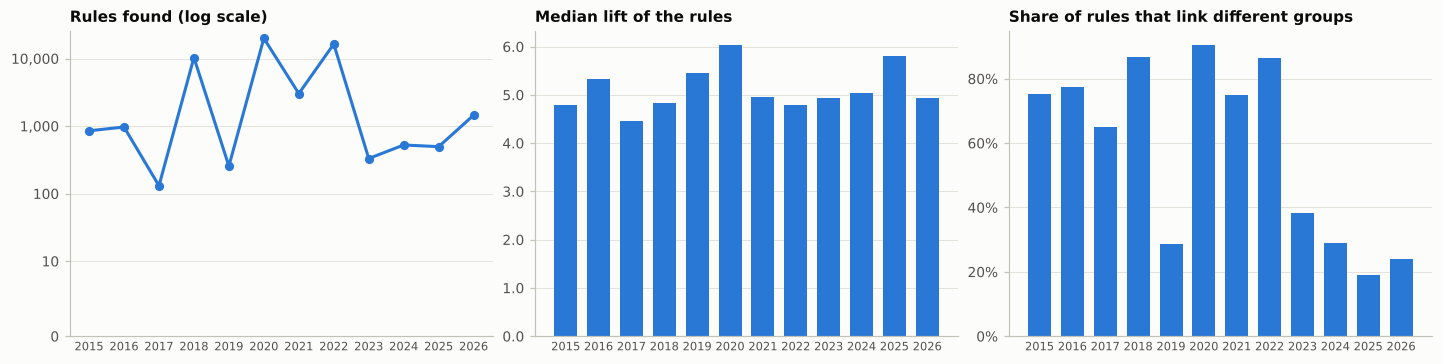

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), layout="constrained")

# Rule counts can differ by a factor of 1,000 between years, so this panel uses a log scale.
axes[0].plot(summary.index, summary["rules"], color="#2a78d6", marker="o", markersize=5)
axes[0].set_yscale("symlog", linthresh=10)
axes[0].set_ylim(bottom=0)
axes[0].set_title("Rules found (log scale)")
axes[0].yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")

for ax, column, title, fmt in [(axes[1], "median_lift", "Median lift of the rules", "{:.1f}"),
                               (axes[2], "cross_group_share", "Share of rules that link different groups", "{:.0%}")]:
    ax.bar(summary.index, summary[column], color="#2a78d6", width=0.7)
    ax.set_title(title)
    ax.yaxis.set_major_formatter(lambda v, _, fmt=fmt: fmt.format(v))

for ax in axes:
    ax.set_xticks(YEARS)
    ax.tick_params(axis="x", labelsize=7.5, length=0)
    ax.grid(axis="y")
    ax.set_axisbelow(True)
save(fig, "6_1_yearly_summary")
plt.show()

### 6.2 How similar is one year's rule set to another's?

For each pair of years we compute the **Jaccard similarity** of their rule sets: rules found in both years divided by rules found in either year. A value of 1 means identical rule sets and 0 means no rule in common. Blocks of similar years show periods when the market kept the same co-movement structure, and a sharp drop between neighbouring years marks a change.

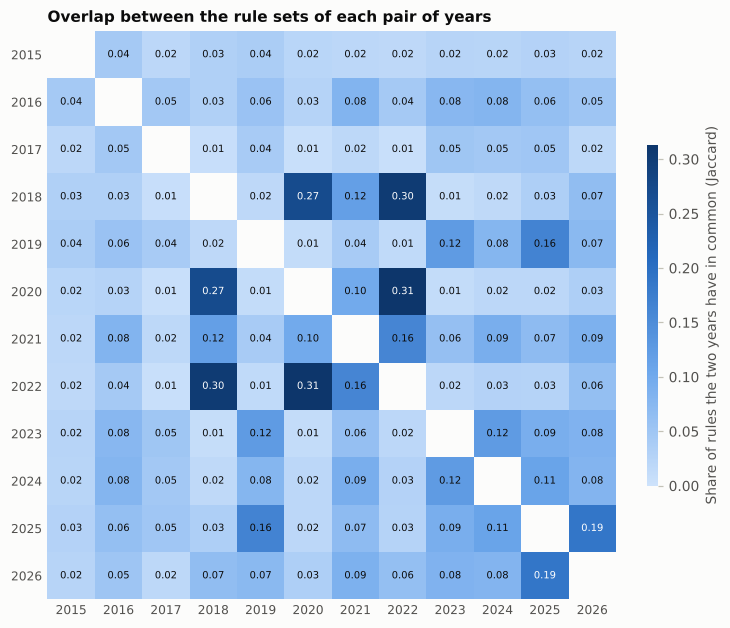

In [21]:
rule_sets = {y: set(r["rule"]) if not r.empty else set() for y, r in rules_by_year.items()}
overlap = pd.DataFrame(index=YEARS, columns=YEARS, dtype=float)
for a in YEARS:
    for b in YEARS:
        either = rule_sets[a] | rule_sets[b]
        overlap.loc[a, b] = len(rule_sets[a] & rule_sets[b]) / len(either) if either else np.nan

fig, ax = plt.subplots(figsize=(6.6, 5.6), layout="constrained")
shown = overlap.to_numpy(dtype=float).copy()
np.fill_diagonal(shown, np.nan)                                     # a year with itself is always 1
image = ax.imshow(shown, cmap=BLUES, vmin=0)
ax.set_xticks(range(len(YEARS)), YEARS, fontsize=8)
ax.set_yticks(range(len(YEARS)), YEARS, fontsize=8)
ax.tick_params(length=0)
ax.spines[:].set_visible(False)
top_value = np.nanmax(shown) if np.isfinite(shown).any() else 1
for i in range(len(YEARS)):
    for j in range(len(YEARS)):
        if i != j and np.isfinite(shown[i, j]):
            ax.text(j, i, f"{shown[i, j]:.2f}", ha="center", va="center", fontsize=6.5,
                    color="white" if shown[i, j] > 0.55 * top_value else INK)
bar = fig.colorbar(image, ax=ax, shrink=0.6, aspect=30)
bar.outline.set_visible(False)
bar.set_label("Share of rules the two years have in common (Jaccard)")
ax.set_title("Overlap between the rule sets of each pair of years")
save(fig, "6_2_rule_overlap_between_years")
plt.show()

### 6.3 Rules that are stable, emerged or disappeared

This is the comparison promised in the proposal, now built on the yearly rule sets. Each two-item rule gets a status from how often it appears before and from `SPLIT_YEAR` onward:

- **stable**: present in at least 60% of the years in both periods
- **emerged**: present in at most one year before the split, and in at least half the years after
- **disappeared**: present in at least half the years before the split, and never after
- **mixed**: everything else

In [22]:
pair_rules = rules_all[rules_all["n_items"] == 2]
lift_table = pair_rules.pivot_table(index="rule", columns="year", values="lift").reindex(columns=YEARS)
present = lift_table.notna()

years_before = [y for y in YEARS if y < SPLIT_YEAR]
years_after = [y for y in YEARS if y >= SPLIT_YEAR]
share_before = present[years_before].mean(axis=1)
share_after = present[years_after].mean(axis=1)

lifecycle = pd.DataFrame({
    "years_present": present.sum(axis=1),
    "share_before": share_before,
    "share_after": share_after,
    "mean_lift": lift_table.mean(axis=1),
})
lifecycle["status"] = np.select(
    [(share_before >= 0.6) & (share_after >= 0.6),
     (present[years_before].sum(axis=1) <= 1) & (share_after >= 0.5),
     (share_before >= 0.5) & (share_after == 0)],
    ["stable", "emerged", "disappeared"], default="mixed")
lifecycle["cross_group"] = pair_rules.groupby("rule")["cross_group"].first()
lifecycle.to_csv(OUT_DIR / "rule_lifecycle.csv")

print("Two-item rules by status, and whether they link different groups:")
pd.crosstab(lifecycle["status"], lifecycle["cross_group"].map({True: "cross-group", False: "within group"}),
            margins=True)

Two-item rules by status, and whether they link different groups:


cross_group,cross-group,within group,All
status,,,
disappeared,115,40,155
emerged,4,17,21
mixed,1159,460,1619
stable,2,34,36
All,1280,551,1831


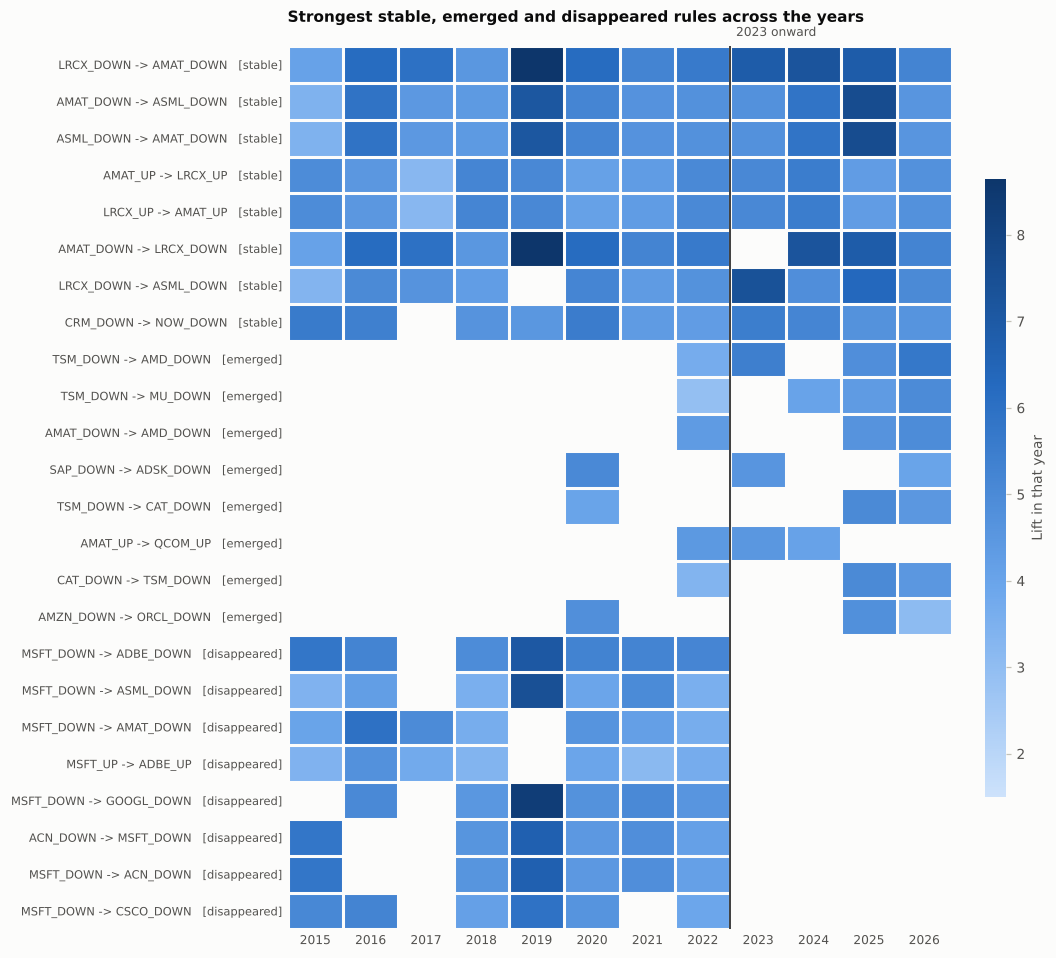

In [23]:
# The strongest rules of each status, shown across the years. A blank cell means the rule was absent that year.
TOP_PER_STATUS = 8
chosen = pd.concat([
    lifecycle[lifecycle["status"] == status].sort_values(["years_present", "mean_lift"], ascending=False).head(TOP_PER_STATUS)
    for status in ["stable", "emerged", "disappeared"]])

if chosen.empty:
    print("No rule was classified as stable, emerged or disappeared with the current thresholds.")
else:
    values = lift_table.loc[chosen.index].to_numpy(dtype=float)
    fig, ax = plt.subplots(figsize=(9.5, 0.3 * len(chosen) + 1.4), layout="constrained")
    image = ax.imshow(values, cmap=BLUES, aspect="auto", vmin=MIN_LIFT)
    ax.set_xticks(range(len(YEARS)), YEARS, fontsize=8)
    ax.set_yticks(range(len(chosen)), [f"{rule}   [{status}]" for rule, status in chosen["status"].items()], fontsize=7.5)
    ax.tick_params(length=0)
    ax.spines[:].set_visible(False)
    ax.set_xticks(np.arange(-0.5, len(YEARS)), minor=True)
    ax.set_yticks(np.arange(-0.5, len(chosen)), minor=True)
    ax.grid(which="minor", color=SURFACE, linewidth=2)               # thin gaps between the cells
    ax.tick_params(which="minor", length=0)
    if years_before and years_after:
        ax.axvline(len(years_before) - 0.5, color=INK, lw=1)
        ax.text(len(years_before) - 0.4, -0.7, f"{SPLIT_YEAR} onward", fontsize=8, color=INK_SOFT, va="bottom")
    bar = fig.colorbar(image, ax=ax, shrink=0.7, aspect=30)
    bar.outline.set_visible(False)
    bar.set_label("Lift in that year")
    ax.set_title("Strongest stable, emerged and disappeared rules across the years", pad=16)
    save(fig, "6_3_rule_lifecycle")
    plt.show()

### 6.4 Co-movement within and between the stock groups

The heatmaps in 5.2 hold 780 pairs per year. Averaging the pair lifts inside each group, and between the AI enablers and each other group, gives one line per group that can be followed through time. The non-tech baseline line is the comparison the professor asked for: if tech co-movement rises while the baseline stays flat, the change is specific to tech and is not the whole market moving.

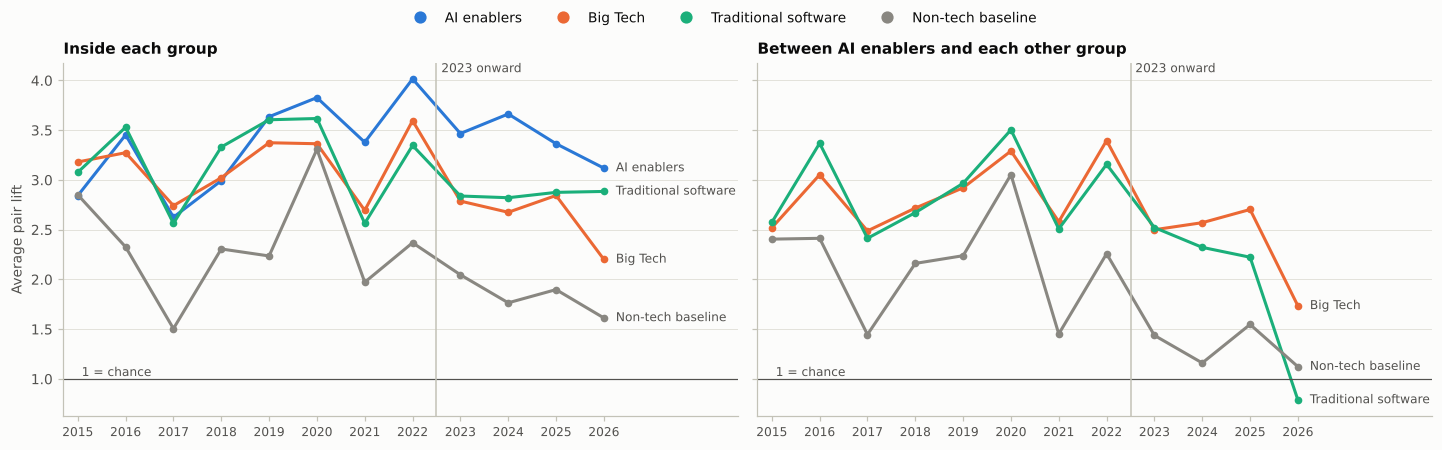

In [24]:
def label_line_ends(ax, table):
    # Name each line at its right-hand end, nudging the labels apart so they never overlap.
    low, high = ax.get_ylim()
    min_gap = 0.055 * (high - low)
    previous = -np.inf
    for group, value in table.iloc[-1].sort_values().items():
        y = max(value, previous + min_gap)
        ax.text(table.index[-1] + 0.25, y, group, va="center", fontsize=8, color=INK_SOFT)
        previous = y


def mean_lift_between(lift, group_a, group_b):
    # Average pair lift between the stocks of two groups (or inside one group when both are the same).
    block = lift.loc[GROUPS_CLEAN[group_a], GROUPS_CLEAN[group_b]].to_numpy()
    return np.nanmean(block)


group_names = list(GROUPS_CLEAN)
anchor = group_names[0]                                             # the AI enablers
within = pd.DataFrame({g: [mean_lift_between(lift_by_year[y], g, g) for y in YEARS] for g in group_names}, index=YEARS)
versus = pd.DataFrame({g: [mean_lift_between(lift_by_year[y], anchor, g) for y in YEARS]
                       for g in group_names[1:]}, index=YEARS)
within.to_csv(OUT_DIR / "group_lift_within.csv")
versus.to_csv(OUT_DIR / "group_lift_vs_first_group.csv")

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True, layout="constrained")
for ax, table, title in [(axes[0], within, "Inside each group"),
                         (axes[1], versus, f"Between {anchor} and each other group")]:
    for group in table.columns:
        ax.plot(table.index, table[group], color=GROUP_COLORS[group], marker="o", markersize=4)
    ax.axhline(1, color=INK_SOFT, lw=0.8)
    ax.text(table.index[0], 1, " 1 = chance", va="bottom", fontsize=8, color=INK_SOFT)
    ax.set_title(title)
    ax.set_xticks(YEARS)
    ax.tick_params(axis="x", labelsize=8)
    ax.grid(axis="y")
    ax.set_xlim(YEARS[0] - 0.3, YEARS[-1] + 2.8)                    # room on the right for the line labels
for ax, table in zip(axes, [within, versus]):                       # labels go on once the shared y-range is final
    label_line_ends(ax, table)
    if years_before and years_after:
        ax.axvline(SPLIT_YEAR - 0.5, color=AXIS, lw=1)
        ax.text(SPLIT_YEAR - 0.4, ax.get_ylim()[1], f"{SPLIT_YEAR} onward", va="top", fontsize=8, color=INK_SOFT)
axes[0].set_ylabel("Average pair lift")
group_legend(fig)
save(fig, "6_4_group_comovement_over_time")
plt.show()

## 7. Are the rules real?

The project guidelines ask how we know we are not fooling ourselves. Two checks.

### 7.1 Do the rules survive a change of support threshold?

We count the rules of every year at each support level in `SUPPORT_GRID`. The baskets are mined once at the lowest support, and the result is filtered for the higher levels. That is valid because a rule's support is the support of its full itemset, so the rules at a higher threshold are exactly the mined rules whose support clears it.

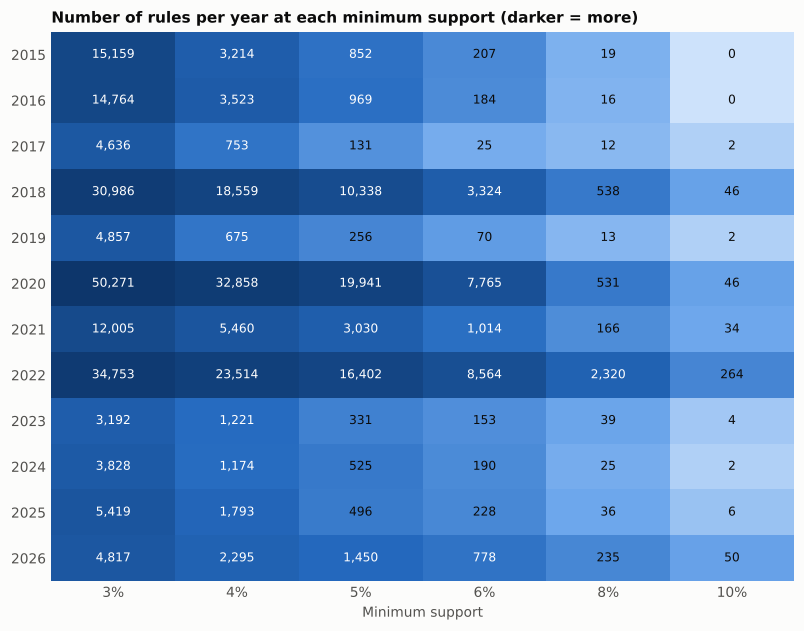

In [25]:
lowest = min(SUPPORT_GRID)
sweep = pd.DataFrame(index=YEARS, columns=SUPPORT_GRID, dtype=float)
for year in YEARS:
    _, rules = mine_rules(baskets_by_year[year], lowest, MIN_CONFIDENCE, MIN_LIFT, MAX_LEN)
    for s in SUPPORT_GRID:
        sweep.loc[year, s] = 0 if rules.empty else (rules["support"] >= s).sum()
sweep = sweep.astype(int)
sweep.to_csv(OUT_DIR / "support_sweep.csv")

fig, ax = plt.subplots(figsize=(7.2, 0.36 * len(YEARS) + 1.3), layout="constrained")
logged = np.log10(sweep.to_numpy(dtype=float) + 1)                  # log scale, so small counts stay visible
ax.imshow(logged, cmap=BLUES, aspect="auto")
ax.set_xticks(range(len(SUPPORT_GRID)), [f"{s:.0%}" for s in SUPPORT_GRID])
ax.set_yticks(range(len(YEARS)), YEARS)
ax.tick_params(length=0)
ax.spines[:].set_visible(False)
for i in range(len(YEARS)):
    for j in range(len(SUPPORT_GRID)):
        ax.text(j, i, f"{sweep.iat[i, j]:,}", ha="center", va="center", fontsize=8,
                color="white" if logged[i, j] > 0.6 * logged.max() else INK)
ax.set_xlabel("Minimum support")
ax.set_title("Number of rules per year at each minimum support (darker = more)")
save(fig, "7_1_support_sweep")
plt.show()

### 7.2 Would shuffled data give the same number of rules?

With about 250 baskets and thousands of candidate rules, some rules will pass the thresholds by luck. To measure how many, we shuffle each item's column independently within the year. Every item keeps exactly the same support, but any link between stocks is destroyed, because each stock's moves now fall on random days. Then we mine the shuffled baskets with the same thresholds. Whatever is found there is the amount of "rules" that chance alone produces.

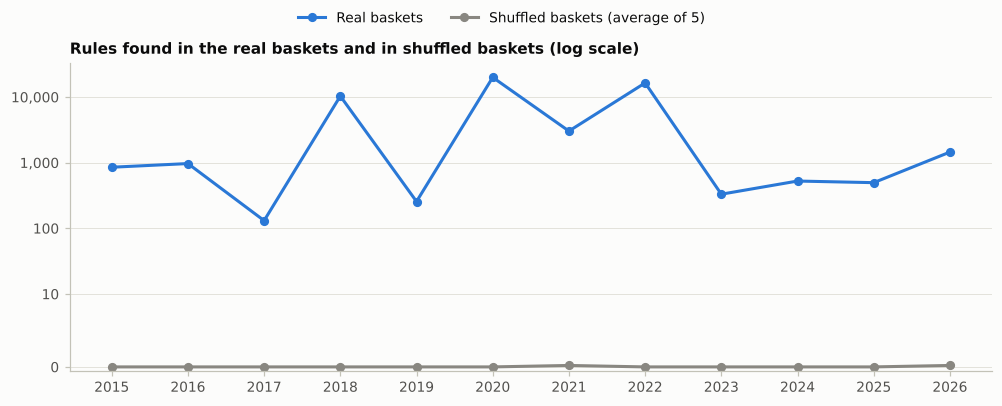

,rules_in_real_data,rules_in_shuffled_data
2015,852,0.0
2016,969,0.0
2017,131,0.0
2018,10338,0.0
2019,256,0.0
2020,19941,0.0
2021,3030,0.2
2022,16402,0.0
2023,331,0.0
2024,525,0.0


In [26]:
def shuffle_items(basket, rng):
    # Shuffle each item column on its own: item supports stay the same, links between items are destroyed.
    return pd.DataFrame({c: rng.permutation(basket[c].to_numpy()) for c in basket.columns}, index=basket.index)


rng = np.random.default_rng(SEED)
chance_rules = {}
for year in YEARS:
    counts = []
    for _ in range(N_SHUFFLES):
        _, rules = mine_rules(shuffle_items(baskets_by_year[year], rng), MIN_SUPPORT, MIN_CONFIDENCE, MIN_LIFT, MAX_LEN)
        counts.append(len(rules))
    chance_rules[year] = np.mean(counts)

shuffle_test = pd.DataFrame({"rules_in_real_data": summary["rules"], "rules_in_shuffled_data": pd.Series(chance_rules)})
shuffle_test.to_csv(OUT_DIR / "shuffle_test.csv")

fig, ax = plt.subplots(figsize=(9, 3.6), layout="constrained")
ax.plot(YEARS, shuffle_test["rules_in_real_data"], color="#2a78d6", marker="o", markersize=5, label="Real baskets")
ax.plot(YEARS, shuffle_test["rules_in_shuffled_data"], color=MUTED, marker="o", markersize=5,
        label=f"Shuffled baskets (average of {N_SHUFFLES})")
ax.set_yscale("symlog", linthresh=10)                               # log scale, but still able to show zero
ax.set_ylim(bottom=-0.5)
ax.set_xticks(YEARS)
ax.grid(axis="y")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
fig.legend(loc="outside upper center", ncol=2, frameon=False)
ax.set_title("Rules found in the real baskets and in shuffled baskets (log scale)")
save(fig, "7_2_shuffle_test")
plt.show()
shuffle_test.round(1)

## 8. Cross-check with clustering

Association rules describe co-movement one rule at a time. Hierarchical clustering gives a second, independent view of the same baskets: group the stocks by how similar their major-move days are, without telling the algorithm which sector each stock belongs to.

- **Distance** between two stocks = Jaccard distance between their move records (UP days and DOWN days). Two stocks are close when they share many major-move days in the same direction.
- **Method** = agglomerative clustering, cut into as many clusters as we have stock groups. We run it with two linkage rules and compare them: **complete** linkage (distance between two clusters = their two farthest stocks) and **average** linkage (the average over all pairs). Average linkage tends to chain stocks on one at a time and leave single-stock clusters, so the two can disagree.
- **Score** = Adjusted Rand Index (ARI) between the clusters and our four groups. ARI 1 means the clusters reproduce the groups exactly, and ARI near 0 means the clusters ignore them.

A falling ARI over the years would say that our sector labels explain less and less of how the stocks actually move.

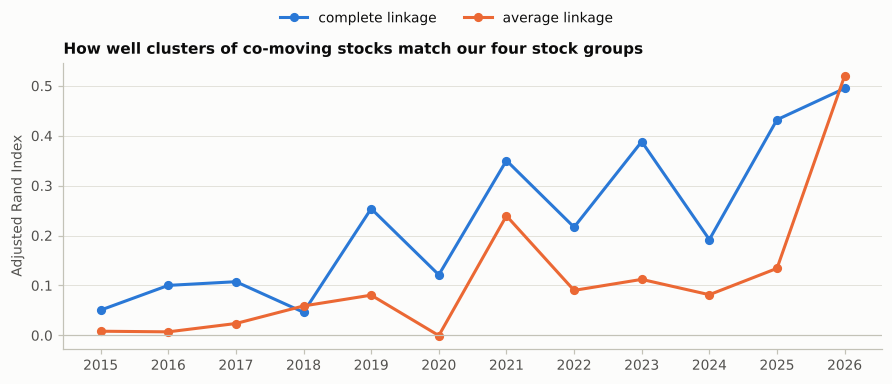

In [27]:
def move_records(basket, tickers):
    # One row per stock: its UP days followed by its DOWN days, as True/False.
    return np.array([np.concatenate([basket[f"{t}_UP"].to_numpy(), basket[f"{t}_DOWN"].to_numpy()]) for t in tickers])


def cluster_stocks(basket, tickers, n_clusters, method):
    # Hierarchical clustering of the stocks for one year. Returns the merge tree and each stock's cluster label.
    distances = pdist(move_records(basket, tickers), metric="jaccard")
    distances = np.nan_to_num(distances, nan=1.0)                   # a stock with no moves is far from everything
    tree = linkage(distances, method=method)
    return tree, fcluster(tree, t=n_clusters, criterion="maxclust")


LINKAGES = {"complete": "#2a78d6", "average": "#eb6834"}            # linkage rule -> line colour
true_groups = [GROUP_OF[t] for t in TICKERS]
trees = {}                                                          # trees[(method, year)] = merge tree
ari = pd.DataFrame(index=YEARS, columns=list(LINKAGES), dtype=float)
for method in LINKAGES:
    for year in YEARS:
        trees[(method, year)], labels = cluster_stocks(baskets_by_year[year], TICKERS, len(GROUPS_CLEAN), method)
        ari.loc[year, method] = adjusted_rand_score(true_groups, labels)
ari.to_csv(OUT_DIR / "cluster_agreement.csv")

fig, ax = plt.subplots(figsize=(8, 3.4), layout="constrained")
for method, color in LINKAGES.items():
    ax.plot(ari.index, ari[method], color=color, marker="o", markersize=5, label=f"{method} linkage")
ax.axhline(0, color=AXIS, lw=0.8)
ax.set_xticks(YEARS)
ax.grid(axis="y")
ax.set_ylabel("Adjusted Rand Index")
fig.legend(loc="outside upper center", ncol=2, frameon=False)
ax.set_title("How well clusters of co-moving stocks match our four stock groups")
save(fig, "8_1_cluster_agreement")
plt.show()

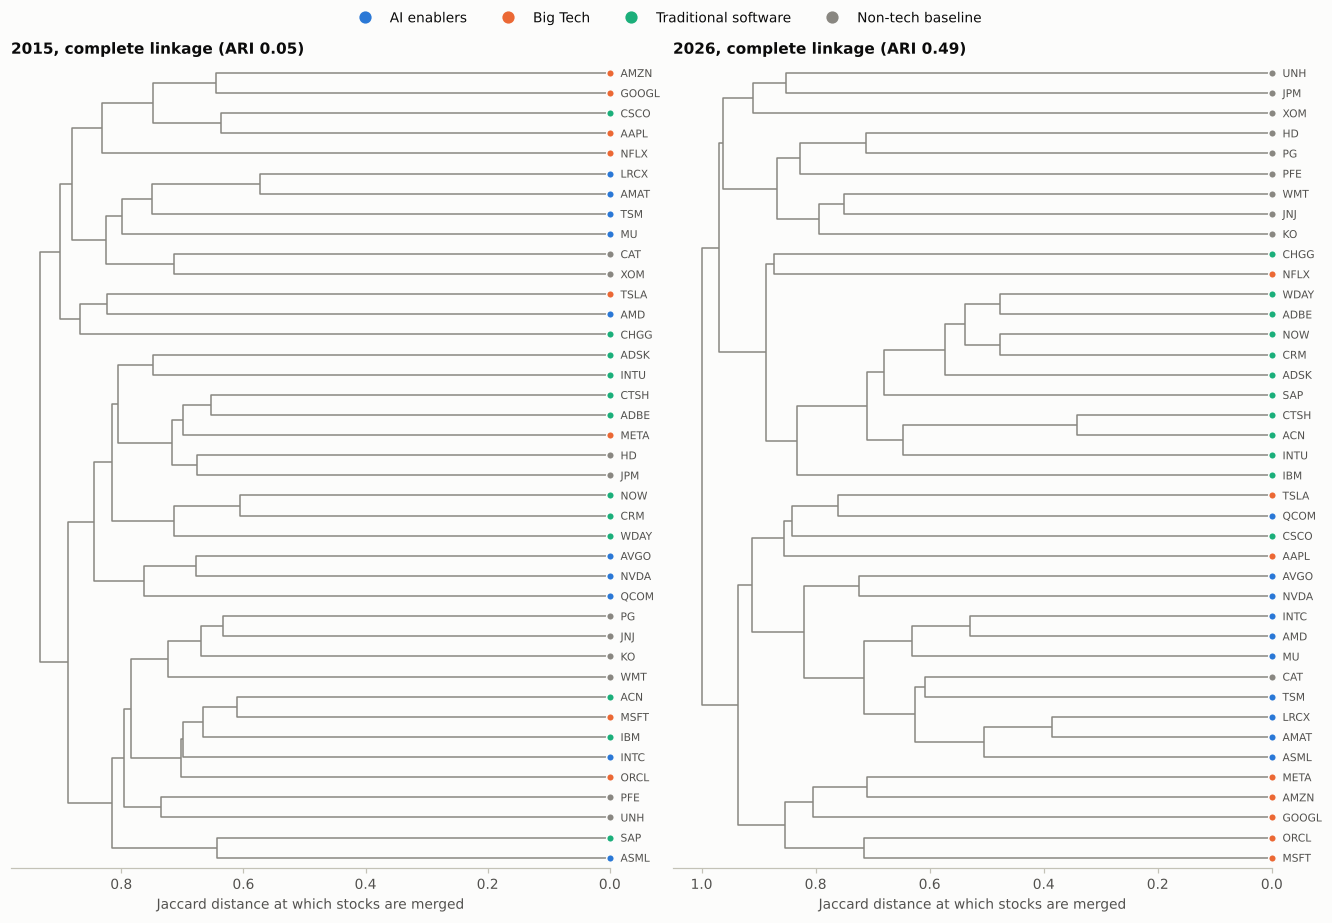

In [28]:
def draw_dendrogram(ax, year, method="complete"):
    # Merge tree for one year. The dot beside each ticker shows which of our groups the stock belongs to.
    with plt.rc_context({"lines.linewidth": 1}):
        drawn = dendrogram(trees[(method, year)], labels=TICKERS, orientation="left", ax=ax, color_threshold=0,
                           above_threshold_color=MUTED, leaf_font_size=7)
    for position, ticker in enumerate(drawn["ivl"]):                # leaves sit at y = 5, 15, 25, ...
        ax.plot(0, 10 * position + 5, marker="o", markersize=5, color=GROUP_COLORS[GROUP_OF[ticker]],
                markeredgecolor=SURFACE, clip_on=False, zorder=3)
    ax.tick_params(axis="y", pad=7, length=0)
    ax.spines["left"].set_visible(False)
    ax.set_xlabel("Jaccard distance at which stocks are merged")
    ax.set_title(f"{year}, {method} linkage (ARI {ari.loc[year, method]:.2f})")


compare_years = [YEARS[0], YEARS[-1]]
fig, axes = plt.subplots(1, 2, figsize=(12, 0.17 * len(TICKERS) + 1.5), layout="constrained")
for ax, year in zip(axes, compare_years):
    draw_dendrogram(ax, year)
group_legend(fig)
save(fig, "8_2_dendrograms")
plt.show()

## 9. Reading the results

Questions to answer from the figures above before writing any conclusion:

1. **Which years stand out in 6.1?** A year with far more rules and larger baskets is usually a market-wide shock (most stocks falling on the same days). Check 5.2 for that year: if the whole heatmap is red, including the baseline block, the rules describe the market and say little about any sector.
2. **Where does the rule set change in 6.2?** Look for a break between neighbouring years and check whether it lines up with `SPLIT_YEAR`.
3. **What does 6.4 show for tech against the baseline?** This is the evidence for or against "tech co-movement changed, and it was not just the market".
4. **Which specific rules emerged or disappeared in 6.3?** Check whether the traditional software names behave the way the proposal expected.
5. **Does 7.2 clear the bar?** If shuffled data gives nearly as many rules as the real data in some year, that year's rules cannot be trusted.
6. **Does 7.1 change the story?** A conclusion should hold at more than one support level.

**Limits of this step.** Rules are same-day only, so they say nothing about one stock leading another. Each year is a fixed calendar window, so a change in the middle of a year is blurred. With `RETURN_MODE = "raw"`, market-wide days are counted as co-movement; switching to `"excess"` removes them.

**Outputs.** Every table is saved as CSV and every figure as PNG in `outputs/step1/`.